<a href="https://colab.research.google.com/github/rogon666/UCB2026/blob/main/UCB_RNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# ==========================================================
#   Maestría en Inteligencia Artificial y Gestión de Datos
#          para Finanzas, Economía y Negocios
# ----------------------------------------------------------
#            Universidad Católica Boliviana
#           Octubre/Noviembre/Diciembre 2026
# ----------------------------------------------------------
#               Aprendizaje Profundo I
# ----------------------------------------------------------
#             Rolando Gonzales Martinez
# ==========================================================
"""
Comparación de RNN, LSTM, GRU, Stacked LSTM y Stacked GRU para predecir
WTI mensual.

Instalación:
    pip install numpy pandas matplotlib scikit-learn tensorflow

Evaluación: predicción a un mes con ventana móvil de 12 meses. Cada
predicción test utiliza observaciones históricas reales disponibles hasta t-1.
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import Dense, SimpleRNN, LSTM, GRU
from tensorflow.keras.callbacks import EarlyStopping

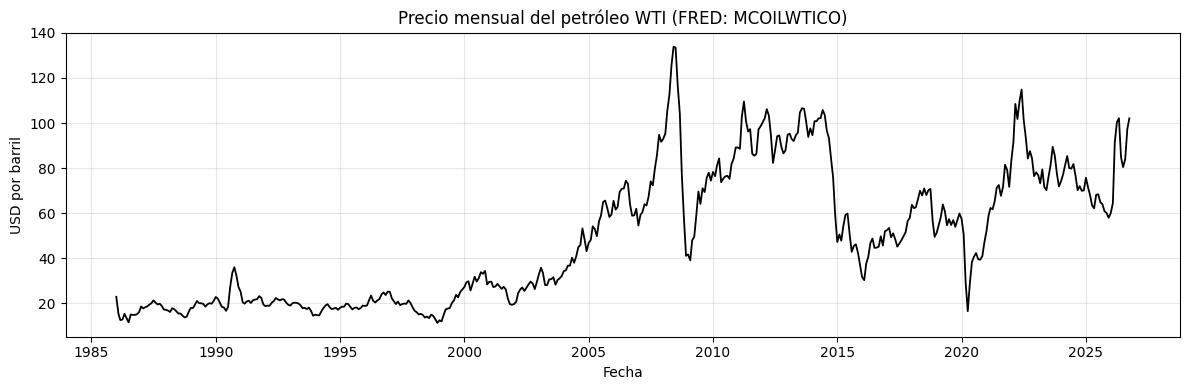

In [15]:

# -------------------------------------------------------------
# 1. CONFIGURACIÓN
# -------------------------------------------------------------
SEMILLA = 42
VENTANA =  6       # Meses utilizados para predecir el siguiente
EPOCAS = 150
LOTE = 16

np.random.seed(SEMILLA)
tf.keras.utils.set_random_seed(SEMILLA)

# -------------------------------------------------------------
# 2. DESCARGAR Y GRAFICAR DATOS DE FRED
# -------------------------------------------------------------
url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=MCOILWTICO"
datos = pd.read_csv(url)
fecha = datos.columns[0]  # En FRED puede llamarse DATE u observation_date
datos[fecha] = pd.to_datetime(datos[fecha])
datos["MCOILWTICO"] = pd.to_numeric(datos["MCOILWTICO"], errors="coerce")
datos = (datos.set_index(fecha)[["MCOILWTICO"]]
         .sort_index().dropna())
plt.figure(figsize=(12, 4))
plt.plot(datos.index, datos["MCOILWTICO"], color="black", linewidth=1.3)
plt.title("Precio mensual del petróleo WTI (FRED: MCOILWTICO)")
plt.ylabel("USD por barril")
plt.xlabel("Fecha")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


Particiones (fechas objetivo):
Entrenamiento: 1986-07-01 a 2014-07-01
Validación:    2014-08-01 a 2020-08-01
Prueba:        2020-09-01 a 2026-10-01


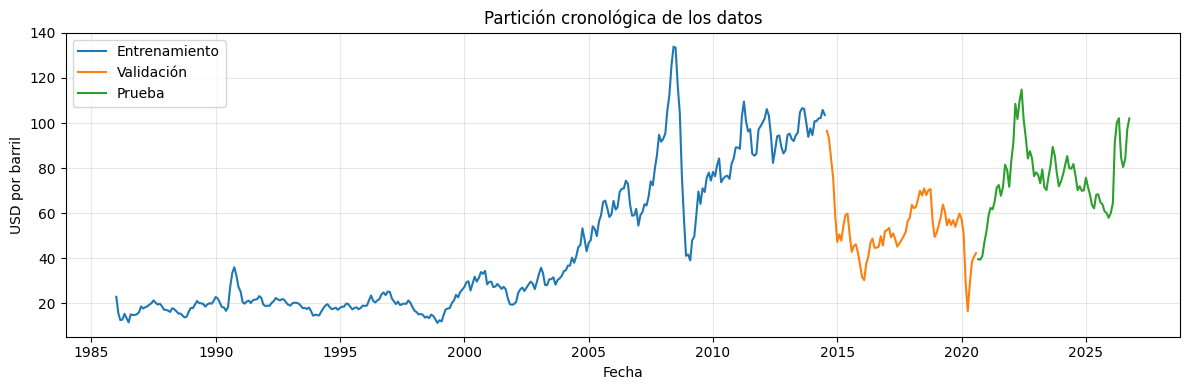

In [16]:
# -------------------------------------------------------------
# 3. PARTICIÓN CRONOLÓGICA 70 % / 15 % / 15 %
# -------------------------------------------------------------
valores = datos[["MCOILWTICO"]].to_numpy(dtype=np.float32)
n = len(valores)
fin_train = int(0.70 * n)
fin_val = int(0.85 * n)

if fin_train <= VENTANA:
    raise ValueError("Muy pocas observaciones para la ventana seleccionada.")

print("\nParticiones (fechas objetivo):")
print("Entrenamiento:", datos.index[VENTANA].date(), "a", datos.index[fin_train - 1].date())
print("Validación:   ", datos.index[fin_train].date(), "a", datos.index[fin_val - 1].date())
print("Prueba:       ", datos.index[fin_val].date(), "a", datos.index[-1].date())

plt.figure(figsize=(12, 4))
plt.plot(datos.index[:fin_train], valores[:fin_train], label="Entrenamiento", color="tab:blue")
plt.plot(datos.index[fin_train:fin_val], valores[fin_train:fin_val],
         label="Validación", color="tab:orange")
plt.plot(datos.index[fin_val:], valores[fin_val:], label="Prueba", color="tab:green")
plt.title("Partición cronológica de los datos")
plt.ylabel("USD por barril")
plt.xlabel("Fecha")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# El escalador se AJUSTA únicamente sobre el entrenamiento (sin fuga de datos).
escalador = StandardScaler()
escalador.fit(valores[:fin_train])
valores_std = escalador.transform(valores)


In [18]:

# -------------------------------------------------------------
# 4. CREAR SECUENCIAS
# -------------------------------------------------------------
def construir_ventanas(serie, ventana):
    X, y, posiciones = [], [], []
    for t in range(ventana, len(serie)):
        X.append(serie[t - ventana:t])
        y.append(serie[t])
        posiciones.append(t)
    return (np.asarray(X, dtype=np.float32),
            np.asarray(y, dtype=np.float32),
            np.asarray(posiciones))

X, y, posiciones = construir_ventanas(valores_std, VENTANA)
mask_train = posiciones < fin_train
mask_val = (posiciones >= fin_train) & (posiciones < fin_val)
mask_test = posiciones >= fin_val

X_train, y_train = X[mask_train], y[mask_train]
X_val, y_val = X[mask_val], y[mask_val]
X_test, y_test = X[mask_test], y[mask_test]
fechas_test = datos.index[posiciones[mask_test]]
y_real = valores[posiciones[mask_test], 0]

print("\nDimensiones de los datos (muestras, meses, variables):")
print("Train:", X_train.shape, "Validación:", X_val.shape, "Test:", X_test.shape)





Dimensiones de los datos (muestras, meses, variables):
Train: (337, 6, 1) Validación: (73, 6, 1) Test: (74, 6, 1)


In [21]:

# -------------------------------------------------------------
# 5. DEFINIR LAS CINCO ARQUITECTURAS
# -------------------------------------------------------------
def crear_modelo(nombre):
    modelo = Sequential(name=nombre.replace(" ", "_"))
    modelo.add(Input(shape=(VENTANA, 1)))

    if nombre == "RNN":
        modelo.add(SimpleRNN(32))
    elif nombre == "LSTM":
        modelo.add(LSTM(32))
    elif nombre == "GRU":
        modelo.add(GRU(32))
    elif nombre == "Stacked LSTM":
        modelo.add(LSTM(32, return_sequences=True))
        modelo.add(LSTM(16))
    elif nombre == "Stacked GRU":
        modelo.add(GRU(32, return_sequences=True))
        modelo.add(GRU(16))
    else:
        raise ValueError(f"Modelo desconocido: {nombre}")

    modelo.add(Dense(1))
    modelo.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
                   loss="mse")
    return modelo

nombres = ["RNN", "LSTM", "GRU", "Stacked LSTM", "Stacked GRU"]
predicciones = {}
historias = {}
resultados = []

In [23]:

# -------------------------------------------------------------
# 6. ENTRENAR Y EVALUAR LOS MODELOS
# -------------------------------------------------------------
def evaluar(nombre, estimado):
    return {"Modelo": nombre,
            "MAE": mean_absolute_error(y_real, estimado),
            "RMSE": np.sqrt(mean_squared_error(y_real, estimado)),
            "R2": r2_score(y_real, estimado)}

for nombre in nombres:
    print(f"\nEntrenando {nombre}...")
    tf.keras.utils.set_random_seed(SEMILLA)  # Inicialización reproducible
    modelo = crear_modelo(nombre)
    parada = EarlyStopping(monitor="val_loss", patience=15,
                           restore_best_weights=True)

    historia = modelo.fit(X_train, y_train,
                          validation_data=(X_val, y_val),
                          epochs=EPOCAS, batch_size=LOTE,
                          callbacks=[parada], shuffle=False, verbose=0)
    historias[nombre] = historia.history

    pred_std = modelo.predict(X_test, verbose=0)
    pred = escalador.inverse_transform(pred_std).ravel()
    predicciones[nombre] = pred
    resultados.append(evaluar(nombre, pred))

    print(f"Épocas: {len(historia.history['loss'])} | "
          f"RMSE test: {resultados[-1]['RMSE']:.2f} USD/barril")

# Benchmark: pronóstico ingenuo P_t = P_(t-1)
pred_naive = valores[posiciones[mask_test] - 1, 0]
predicciones["Naive (último precio)"] = pred_naive
resultados.append(evaluar("Naive (último precio)", pred_naive))

# -------------------------------------------------------------
# 7. TABLA COMPARATIVA
# -------------------------------------------------------------
tabla = pd.DataFrame(resultados).sort_values("RMSE").reset_index(drop=True)
print("\nRESULTADOS SOBRE EL CONJUNTO DE PRUEBA:")
print(tabla.round(3).to_string(index=False))
tabla.to_csv("resultados_modelos_WTI.csv", index=False)


Entrenando RNN...
Épocas: 118 | RMSE test: 6.51 USD/barril

Entrenando LSTM...
Épocas: 17 | RMSE test: 17.97 USD/barril

Entrenando GRU...
Épocas: 17 | RMSE test: 13.15 USD/barril

Entrenando Stacked LSTM...
Épocas: 17 | RMSE test: 24.12 USD/barril

Entrenando Stacked GRU...
Épocas: 51 | RMSE test: 7.49 USD/barril

RESULTADOS SOBRE EL CONJUNTO DE PRUEBA:
               Modelo    MAE   RMSE     R2
                  RNN  4.983  6.515  0.822
                  RNN  4.983  6.515  0.822
Naive (último precio)  5.210  6.811  0.806
Naive (último precio)  5.210  6.811  0.806
          Stacked GRU  5.557  7.489  0.765
          Stacked GRU  5.557  7.489  0.765
                  GRU  9.704 13.146  0.277
                  GRU  9.704 13.146  0.277
                 LSTM 14.574 17.972 -0.351
                 LSTM 14.574 17.972 -0.351
         Stacked LSTM 21.117 24.119 -1.433
         Stacked LSTM 21.117 24.119 -1.433


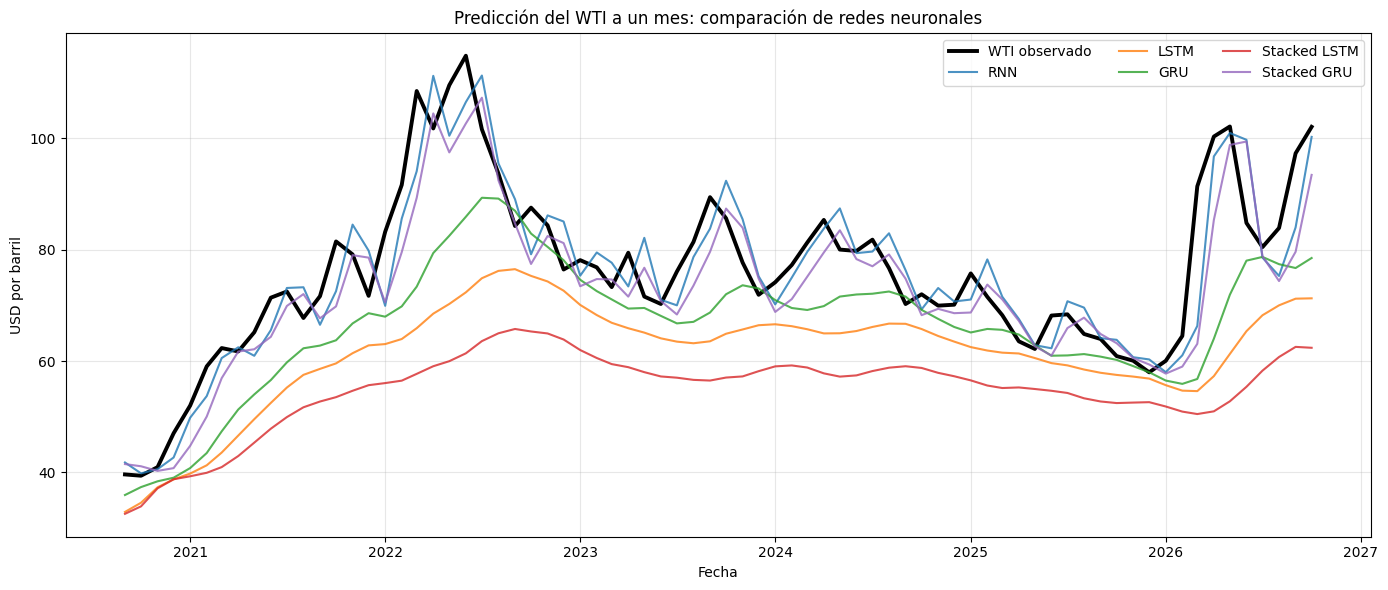

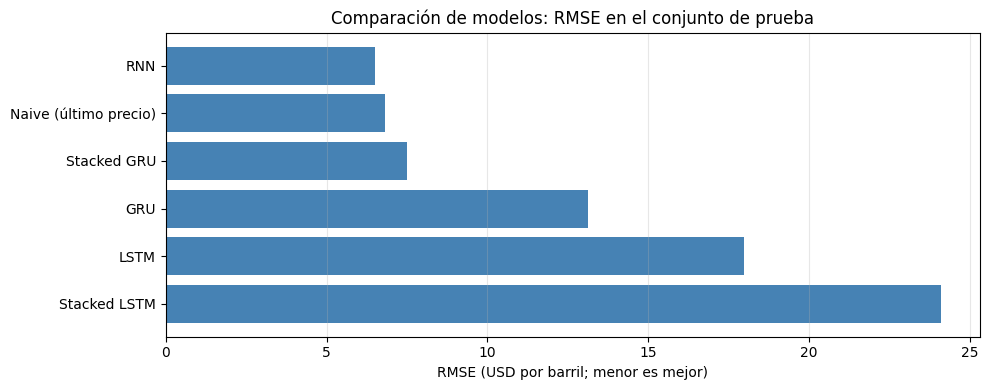

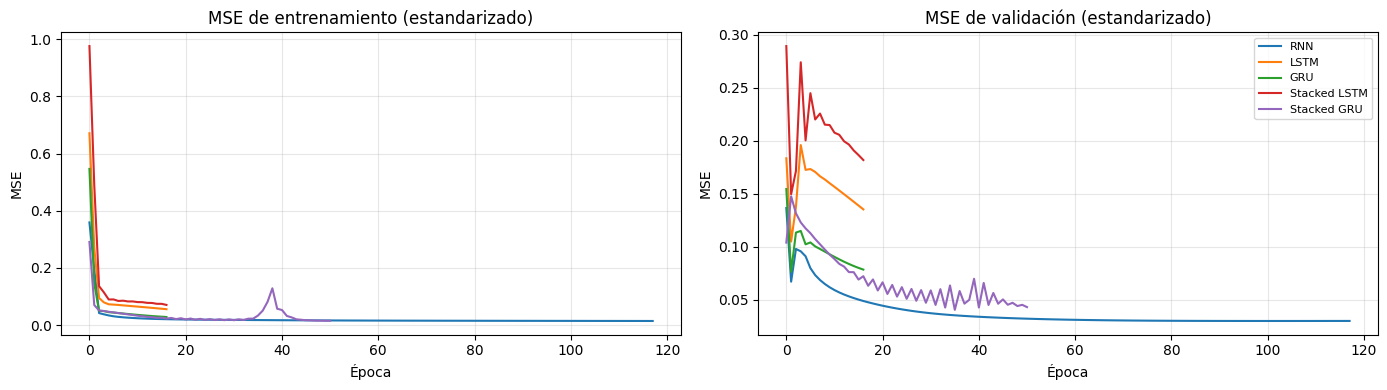

In [24]:

# -------------------------------------------------------------
# 8. GRAFICAR PREDICCIONES
# -------------------------------------------------------------
plt.figure(figsize=(14, 6))
plt.plot(fechas_test, y_real, label="WTI observado", color="black", linewidth=2.8)
for nombre in nombres:
    plt.plot(fechas_test, predicciones[nombre], label=nombre, alpha=0.8, linewidth=1.5)
plt.title("Predicción del WTI a un mes: comparación de redes neuronales")
plt.ylabel("USD por barril")
plt.xlabel("Fecha")
plt.legend(ncol=3)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# -------------------------------------------------------------
# 9. COMPARACIÓN DE RMSE
# -------------------------------------------------------------
plt.figure(figsize=(10, 4))
plt.barh(tabla["Modelo"], tabla["RMSE"], color="steelblue")
plt.gca().invert_yaxis()
plt.title("Comparación de modelos: RMSE en el conjunto de prueba")
plt.xlabel("RMSE (USD por barril; menor es mejor)")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

# -------------------------------------------------------------
# 10. CURVAS DE APRENDIZAJE
# -------------------------------------------------------------
fig, ejes = plt.subplots(1, 2, figsize=(14, 4))
for nombre in nombres:
    ejes[0].plot(historias[nombre]["loss"], label=nombre)
    ejes[1].plot(historias[nombre]["val_loss"], label=nombre)
ejes[0].set_title("MSE de entrenamiento (estandarizado)")
ejes[1].set_title("MSE de validación (estandarizado)")
for ax in ejes:
    ax.set_xlabel("Época")
    ax.set_ylabel("MSE")
    ax.grid(alpha=0.3)
ejes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

# Predicciones individuales para análisis posterior.
pd.DataFrame({"WTI_observado": y_real, **predicciones},
             index=fechas_test).to_csv("predicciones_modelos_WTI.csv",
                                      index_label="fecha")
